In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-poster')

In [2]:
import src.Retrieval as retrieval

In [3]:
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'default'

r = retrieval.Retrieval(EXPERIMENT)
r.load_retrieval()

In [4]:
misr_list = r.obs['MISR']['sensor_list']
at3d_list = r.sensors_retrieval['MISR']['sensor_list']

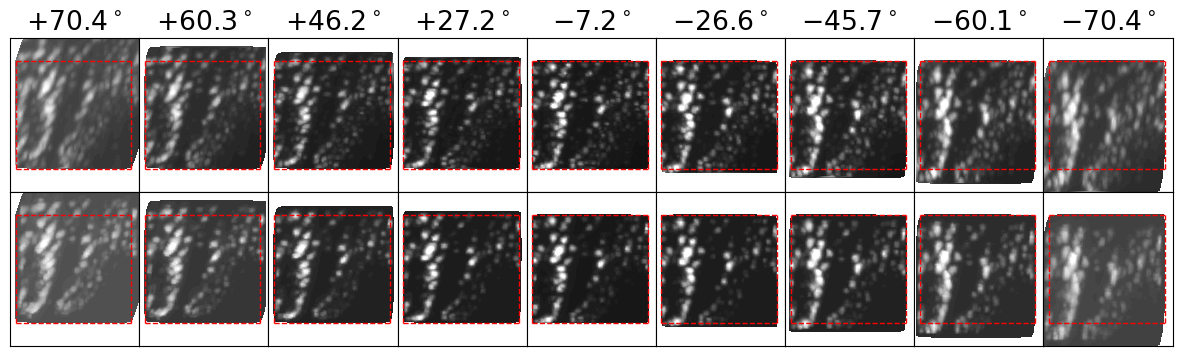

In [30]:
vrange = 0.18
plot_kwargs = {
    'cmap':'gray',
    'vmin':0,
    'vmax':0.4,
    'levels':np.linspace(0, 0.4, 50)
}
diff_kwargs = {
    'cmap':'RdBu_r',
    'vmin':-vrange,
    'vmax':vrange,
    'levels':np.linspace(-vrange, vrange, 100)
}

f, ax = plt.subplots(2, 9, figsize=(15,4), sharex=True, sharey=True)
f.subplots_adjust(wspace=0, hspace=0)

for i, (misr, at3d) in enumerate(zip(misr_list, at3d_list)):
    ax[0,i].tricontourf(misr.cam_x, misr.cam_y, misr.brf, **plot_kwargs)
    ax[1,i].tricontourf(at3d.cam_x, at3d.cam_y, at3d.brf, **plot_kwargs)
    # ax[2,i].tricontourf(at3d.cam_x.data, at3d.cam_y.data, at3d.brf.data - misr.brf.data, **diff_kwargs)
    tmp_zenith = np.degrees(np.arccos(np.unique(misr.cam_mu.data)))[0]
    tmp_azimuth = np.degrees(np.unique(misr.cam_phi.data))[0]
    if(tmp_azimuth < 200):
        ax[0,i].set_title(f'$+{tmp_zenith:.1f}^\circ$')
    else:
        ax[0,i].set_title(f'$-{tmp_zenith:.1f}^\circ$')

# xticks = [8.8, 17.6]
# yticks = [0.0, 8.8, 17.6]
xticks = []
yticks = []
box_kwargs = {'ls':'--', 'lw':1.0, 'c':'r'}
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [0, 0], **box_kwargs)
    a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
    a.set_xticks(xticks)
    a.set_xticklabels(xticks, rotation=45)
    a.set_yticks(yticks)